<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and fixture design](README.md)

# 01 · Does an incident expansion contain all its alerts?

An incident feed can include a convenient nested alert list, but that list has a cap. Can we use it to count alerts or describe their severity mix?

We will compare capped incident expansions with the authoritative alert feed, using **entirely synthetic input records through the real Defender worker functions**. The published release supplies metadata; a companion harness imports that release's original table functions, schemas, paging and watermark logic and injects the repository's shipped fake Graph client. **No Azure tenant is contacted.** This makes the completeness problem reproducible without account data.

## Choose the expansion cap

`MAX_INLINE_ALERTS` is the maximum nested alerts requested per incident, from 1 to 10 in this example. The final experiment changes only **2 → 4**. Restart the kernel and run all after editing.

The finite fixture contains three incidents and their alert lists. All event timestamps are **2024-01-01 UTC**. Scans use the inclusive lower bound `since = 2024-01-01T00:00:00Z`; the fixture contains no other dates. Its ordering deliberately makes the first alerts unrepresentative. This is a counterexample to treating a capped list as a sample, not an estimate of typical tenant behavior.

In [1]:
MAX_INLINE_ALERTS = 2  # Integer 1–10; final experiment: 4

In [2]:
import hashlib
import json
import os
import tempfile
from datetime import datetime, timezone
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

assert isinstance(MAX_INLINE_ALERTS, int) and not isinstance(MAX_INLINE_ALERTS, bool)
assert 1 <= MAX_INLINE_ALERTS <= 10
NOTEBOOK_DIR = Path.cwd()
fixture_bytes = (NOTEBOOK_DIR / "fixture.json").read_bytes()
fixture_input = json.loads(fixture_bytes)
fixture_hash = hashlib.sha256(fixture_bytes).hexdigest()
started_utc = datetime.now(timezone.utc)
assert started_utc >= datetime(2024,1,2,tzinfo=timezone.utc)
scratch = tempfile.TemporaryDirectory(prefix="vgi-defender-notebook-")
trace_path = Path(scratch.name) / "fetches.jsonl"
trace_path.write_text("")
os.environ["VGI_DEFENDER_FIXTURE_TRACE"] = str(trace_path)
os.environ["PLOOMBER_STATS_ENABLED"] = "false"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi":125,"text.parse_math":False,"axes.spines.top":False,"axes.spines.right":False})
INLINE, FULL = "#aa7636", "#217b9c"
def prose(text):display(Markdown(text))
def finish(fig):
    fig.text(.01,.01,f"Source: synthetic fixture.json · real Defender v0.4.0 functions · nested cap {MAX_INLINE_ALERTS}",fontsize=8,color="#555555")
    fig.tight_layout(rect=(0,.05,1,.96));plt.show()
fixture_secret_directory = tempfile.TemporaryDirectory(prefix="vgi-fixture-secrets-")
con = haybarn.connect(config={"secret_directory": fixture_secret_directory.name, "allow_persistent_secrets": False})
assert con.execute("SELECT name, persistent, storage FROM duckdb_secrets()").fetchall() == [], "Fixture must start without SQL secrets"
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline


/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-defender/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-defender/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-defender/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-defender/notebooks/pyproject.toml.

## Two connections with different roles

`published` attaches the actual v0.4.0 binary for credential-free feed discovery. `fixture` launches a local companion that fetches the same release's immutable source commit, installs its frozen Bun dependencies, and runs the **unchanged** production functions with the shipped `FakeDefender` client. The fixture's runtime network access is disabled.

The dummy secret below contains no credential. It satisfies the functions' secret lookup; the injected client ignores it. Run All does not exercise MSAL authentication, HTTP retries, Graph permission checks or a live tenant. The [README](README.md) explains the separate live prerequisite without executing it.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'azure' AS published (
    TYPE vgi,
    LOCATION 'github-auto://Query-farm/vgi-azure-defender@v0.4.0'
);
ATTACH 'azure' AS fixture (
    TYPE vgi,
    LOCATION 'bun run defender_fixture.ts Query-farm/vgi-azure-defender 08d098b6991c98c6ac4fbeaa13c5e9caf12e5e7d fixture.json'
);
CREATE TEMPORARY SECRET synthetic_fixture_input (
    TYPE azure_graph,
    TENANT_ID '00000000-0000-0000-0000-000000000000',
    CLIENT_ID '00000000-0000-0000-0000-000000000000',
    CLIENT_SECRET 'synthetic-not-a-credential'
);

,Success


In [4]:
fixture_secrets = con.execute("SELECT name, persistent, storage FROM duckdb_secrets() ORDER BY name").fetchall()
assert fixture_secrets == [('synthetic_fixture_input', False, 'memory')], "Only the public temporary fixture secrets may exist"

In [5]:
%%sql feeds <<
SELECT feed, source_endpoint, row_kinds, requires_secret
FROM published.main.feeds ORDER BY feed;

In [6]:
display(feeds)
prose(f"**Synthetic fixture SHA-256:** `{fixture_hash}`. "
      f"Executed **{started_utc:%Y-%m-%d %H:%M:%S UTC}**; this is an execution clock, not an event date. "
      "The metadata identifies two distinct feeds. Their marker rows carry cursors and must not be counted as incidents or alerts.")

,feed,source_endpoint,row_kinds,requires_secret
0,security_alerts,/security/alerts_v2,"alert, marker",True
1,security_incidents,/security/incidents?$expand=alerts,"incident, alert, marker",True


**Synthetic fixture SHA-256:** `5fe442fde129755ea56b428317565ed8b79d00c4132d0536a8fbd5a34e9d6d2a`. Executed **2026-11-14 10:57:16 UTC**; this is an execution clock, not an event date. The metadata identifies two distinct feeds. Their marker rows carry cursors and must not be counted as incidents or alerts.

## Materialize each scan once

The first result interleaves `incident`, nested `alert` and final `marker` rows. The second yields authoritative `alert` rows and its own marker. Keeping both scans as ordinary in-memory tables prevents tables and charts from repeating source requests.

The shipped fake pages at two source objects per page, so these calls exercise the original pager rather than handing a prebuilt Arrow result to DuckDB. The companion only substitutes the API client; mapping, truncation flags and marker generation remain production code.

In [7]:
%%sql
CREATE TABLE inline_scan AS
SELECT * FROM fixture.main.security_incidents(
    since := '2024-01-01T00:00:00Z', max_alerts := '{{MAX_INLINE_ALERTS}}'
);
CREATE TABLE authoritative_scan AS
SELECT * FROM fixture.main.security_alerts(since := '2024-01-01T00:00:00Z');

,Count


In [8]:
%%sql diagnostics <<
WITH rows AS (
    SELECT 'incident expansion' AS feed, _row_kind, last_update_datetime, _watermark_next FROM inline_scan
    UNION ALL
    SELECT 'authoritative alerts', _row_kind, last_update_datetime, _watermark_next FROM authoritative_scan
)
SELECT feed, count(*) FILTER (WHERE _row_kind = 'incident') AS incident_rows,
       count(*) FILTER (WHERE _row_kind = 'alert') AS alert_rows,
       count(*) FILTER (WHERE _row_kind = 'marker') AS marker_rows,
       max(last_update_datetime::TIMESTAMPTZ) AS latest_update_utc,
       max(_watermark_next::TIMESTAMPTZ) AS next_watermark_utc
FROM rows GROUP BY feed ORDER BY feed;

In [9]:
display(diagnostics)
assert (diagnostics.marker_rows == 1).all()
assert (diagnostics.next_watermark_utc <= diagnostics.latest_update_utc).all()
requests = [json.loads(line)["url"] for line in trace_path.read_text().splitlines()]
request_counts = pd.DataFrame({"feed":["incident expansion","authoritative alerts"],
    "fixture_pages":[sum("/security/incidents?" in u for u in requests),sum("/security/alerts_v2?" in u for u in requests)]})
display(request_counts)
assert (request_counts.fixture_pages > 1).all()
lag_minutes = (diagnostics.latest_update_utc - diagnostics.next_watermark_utc).dt.total_seconds()/60
assert (lag_minutes == 10).all()
prose(f"Both scans returned exactly one marker. Their returned watermarks lag the latest data timestamp by "
      f"**{lag_minutes.iloc[0]:g} minutes** in this fixture. "
      "The worker deliberately overlaps later scans to re-read recent updates; downstream application should be idempotent by ID. "
      "The marker is a cursor, not an extra alert or an assertion that capped children are complete. "
      f"The fixture served **{len(requests)} pages** across the two materialized scans.")

,feed,incident_rows,alert_rows,marker_rows,latest_update_utc,next_watermark_utc
0,authoritative alerts,0,12,1,2024-01-01 05:00:00-05:00,2024-01-01 04:50:00-05:00
1,incident expansion,3,5,1,2024-01-01 05:00:00-05:00,2024-01-01 04:50:00-05:00


,feed,fixture_pages
0,incident expansion,2
1,authoritative alerts,6


Both scans returned exactly one marker. Their returned watermarks lag the latest data timestamp by **10 minutes** in this fixture. The worker deliberately overlaps later scans to re-read recent updates; downstream application should be idempotent by ID. The marker is a cursor, not an extra alert or an assertion that capped children are complete. The fixture served **8 pages** across the two materialized scans.

## Reconcile the incident counts

For each incident, compare its reported `alert_count`, the nested rows actually returned, and the authoritative rows joined by `incident_id`. A marker's NULL ID must not enter that join. We use a left join so an incident with no matching alerts remains visible.

The authoritative result is complete **for this finite fixture and scan window**. In a live system, the two scans are not an atomic snapshot, and different update windows can create mismatches; a join alone cannot prove tenant-wide completeness.

In [10]:
%%sql coverage <<
WITH incidents AS (
    SELECT id, display_name, alert_count, _alerts_truncated
    FROM inline_scan WHERE _row_kind = 'incident'
), nested AS (
    SELECT incident_id, count(DISTINCT id) AS returned_inline
    FROM inline_scan WHERE _row_kind = 'alert' GROUP BY incident_id
), full_feed AS (
    SELECT incident_id, count(DISTINCT id) AS authoritative_count
    FROM authoritative_scan WHERE _row_kind = 'alert' GROUP BY incident_id
)
SELECT i.id, i.display_name, i.alert_count AS reported_count,
       coalesce(n.returned_inline,0) AS returned_inline,
       coalesce(f.authoritative_count,0) AS authoritative_count,
       i._alerts_truncated,
       coalesce(f.authoritative_count,0) - coalesce(n.returned_inline,0) AS absent_inline
FROM incidents i LEFT JOIN nested n ON i.id=n.incident_id
LEFT JOIN full_feed f ON i.id=f.incident_id
ORDER BY authoritative_count DESC,i.id;

,id,display_name,reported_count,returned_inline,authoritative_count,_alerts_truncated,absent_inline
0,inc-bulk,Synthetic bulk correlation,7,2,7,True,5
1,inc-mail,Synthetic mail investigation,4,2,4,True,2
2,inc-single,Synthetic isolated review,1,1,1,False,0


At cap **2**, the incident expansions contain **5 of 12 alerts (41.7%)**; **7** are absent from the nested rows. **2 of 3 incidents** are flagged as truncated. The authoritative counts agree with the fixture's reported incident counts. Zero from the left join means no returned matching row; in a live scan it would not prove that no alert ever existed.

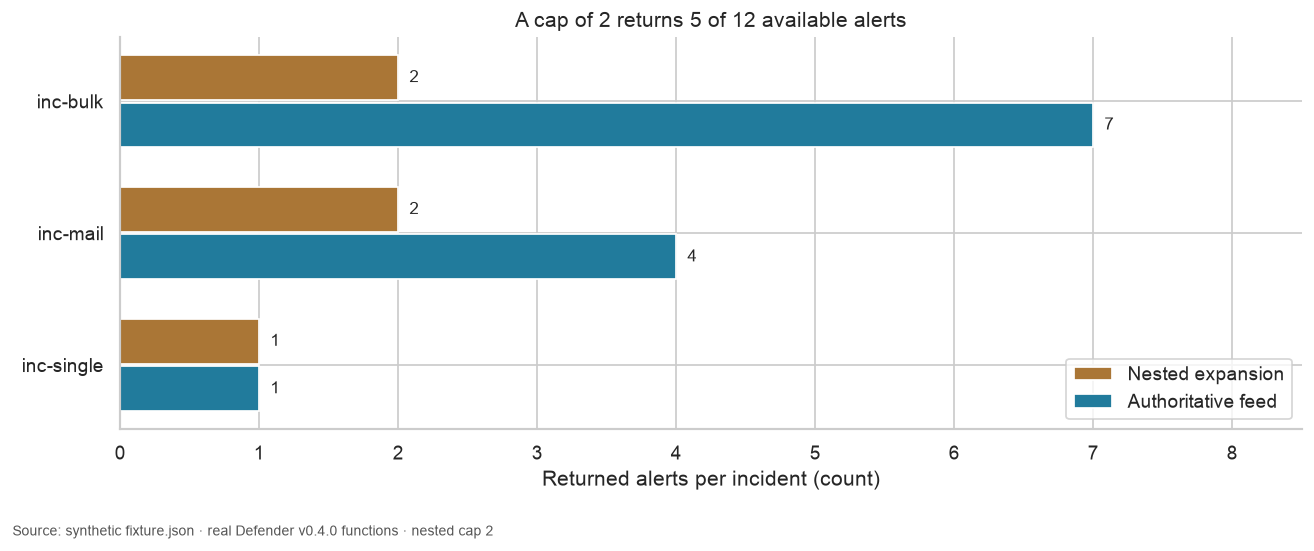

In [11]:
display(coverage)
assert (coverage.reported_count == coverage.authoritative_count).all()
assert (coverage.returned_inline <= coverage.authoritative_count).all()
assert (coverage._alerts_truncated == (coverage.absent_inline > 0)).all()
returned = int(coverage.returned_inline.sum());total = int(coverage.authoritative_count.sum())
truncated = int(coverage._alerts_truncated.sum())
prose(f"At cap **{MAX_INLINE_ALERTS}**, the incident expansions contain **{returned} of {total} alerts "
      f"({returned/total:.1%})**; **{total-returned}** are absent from the nested rows. "
      f"**{truncated} of {len(coverage)} incidents** are flagged as truncated. "
      "The authoritative counts agree with the fixture's reported incident counts. Zero from the left join means no returned matching row; "
      "in a live scan it would not prove that no alert ever existed.")
fig,ax=plt.subplots(figsize=(10.6,4.6));y=np.arange(len(coverage))
ax.barh(y-.18,coverage.returned_inline,height=.34,color=INLINE,label="Nested expansion")
ax.barh(y+.18,coverage.authoritative_count,height=.34,color=FULL,label="Authoritative feed")
for i,row in coverage.iterrows():
    ax.text(row.returned_inline+.08,i-.18,str(int(row.returned_inline)),va="center",fontsize=10)
    ax.text(row.authoritative_count+.08,i+.18,str(int(row.authoritative_count)),va="center",fontsize=10)
ax.set_yticks(y,coverage.id);ax.invert_yaxis()
ax.set(xlabel="Returned alerts per incident (count)",xlim=(0,coverage.authoritative_count.max()+1.5),
       title=f"A cap of {MAX_INLINE_ALERTS} returns {returned} of {total} available alerts")
ax.legend(loc="lower right");finish(fig)

## Missing children change the apparent severity mix

A cap does not draw a random sample. In this fixture, the beginning of the bulk incident's list contains lower-severity alerts, while later entries contain several high-severity alerts. SQL calculates counts and percentages separately for each returned population.

The denominator for the expansion is **only the alerts it returned**, not the authoritative total. Missing children have unknown severity from that expansion alone; they must not be treated as zero high-severity alerts.

In [12]:
%%sql severity <<
WITH observed AS (
    SELECT 'Nested expansion' AS feed, coalesce(severity,'unknown') AS severity
    FROM inline_scan WHERE _row_kind='alert'
    UNION ALL
    SELECT 'Authoritative feed',coalesce(severity,'unknown')
    FROM authoritative_scan WHERE _row_kind='alert'
), categories AS (
    SELECT * FROM (VALUES ('informational',1),('low',2),('medium',3),('high',4),('unknown',5)) t(severity,sort_order)
), feeds AS (
    SELECT DISTINCT feed FROM observed
), counts AS (
    SELECT feed,severity,count(*) AS alerts FROM observed GROUP BY feed,severity
)
SELECT f.feed,c.severity,c.sort_order,coalesce(n.alerts,0) AS alerts,
       coalesce(n.alerts,0)::DOUBLE / sum(coalesce(n.alerts,0)) OVER (PARTITION BY f.feed) AS share
FROM feeds f CROSS JOIN categories c LEFT JOIN counts n USING (feed,severity)
ORDER BY c.sort_order,f.feed;

,feed,severity,alerts,share
0,Authoritative feed,informational,1,0.083333
1,Nested expansion,informational,1,0.200000
2,Authoritative feed,low,3,0.250000
3,Nested expansion,low,1,0.200000
4,Authoritative feed,medium,3,0.250000
5,Nested expansion,medium,2,0.400000
6,Authoritative feed,high,5,0.416667
7,Nested expansion,high,1,0.200000
8,Authoritative feed,unknown,0,0.000000
9,Nested expansion,unknown,0,0.000000


High-severity alerts are **1 / 5 (20.0%)** in the expansion, compared with **5 / 12 (41.7%)** in the authoritative feed. The difference is caused by which synthetic rows the cap omitted. It is not evidence of a different underlying incident population.

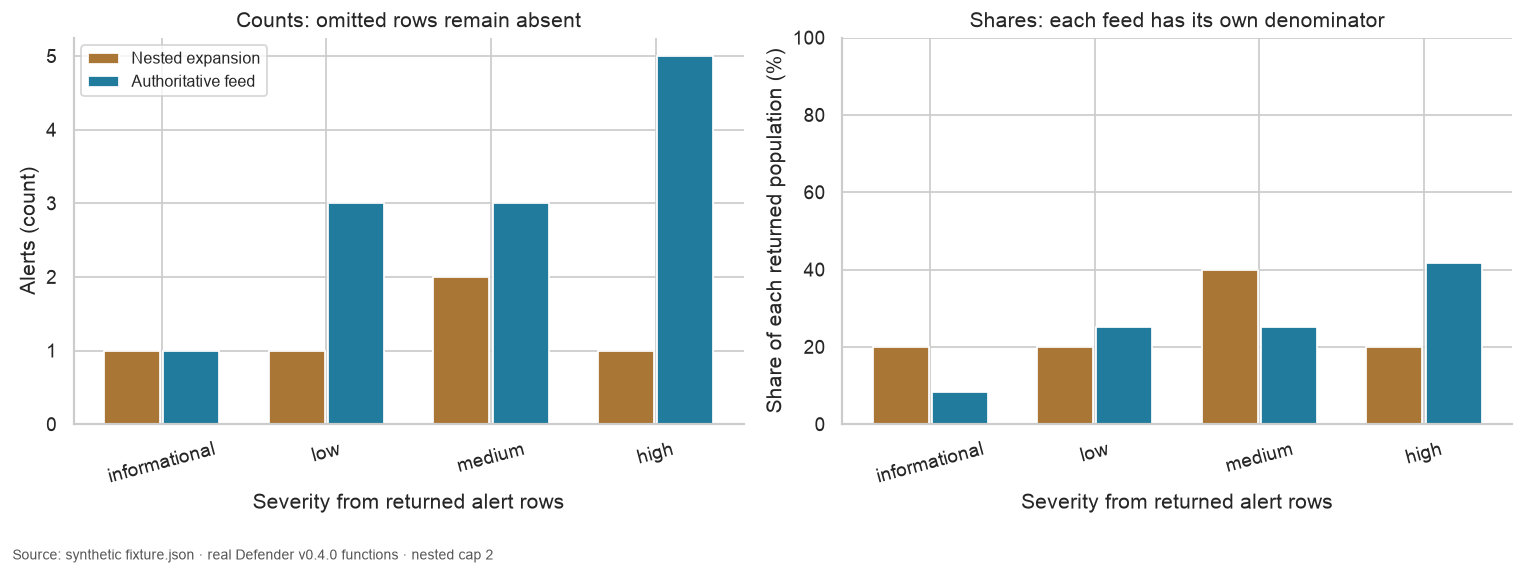

In [13]:
display(severity[["feed","severity","alerts","share"]])
high=severity[severity.severity=="high"].set_index("feed")
prose(f"High-severity alerts are **{int(high.loc['Nested expansion','alerts'])} / {returned} "
      f"({high.loc['Nested expansion','share']:.1%})** in the expansion, compared with "
      f"**{int(high.loc['Authoritative feed','alerts'])} / {total} "
      f"({high.loc['Authoritative feed','share']:.1%})** in the authoritative feed. "
      "The difference is caused by which synthetic rows the cap omitted. It is not evidence of a different underlying incident population.")
shown=severity.groupby("severity").alerts.sum();categories=[s for s in ["informational","low","medium","high","unknown"] if shown[s]>0]
fig,axes=plt.subplots(1,2,figsize=(12.3,4.8));x=np.arange(len(categories))
for offset,feed,color in [(-.18,"Nested expansion",INLINE),(.18,"Authoritative feed",FULL)]:
    values=severity[severity.feed==feed].set_index("severity").loc[categories]
    axes[0].bar(x+offset,values.alerts,width=.34,label=feed,color=color)
    axes[1].bar(x+offset,values.share*100,width=.34,label=feed,color=color)
for ax in axes:
    ax.set_xticks(x,categories,rotation=15);ax.set_xlabel("Severity from returned alert rows")
axes[0].set(ylabel="Alerts (count)",title="Counts: omitted rows remain absent")
axes[1].set(ylabel="Share of each returned population (%)",ylim=(0,100),title="Shares: each feed has its own denominator")
axes[0].legend(fontsize=9);finish(fig)

## One change to test

Change only **`MAX_INLINE_ALERTS` from `2` to `4`** and execute a separate experiment copy. Predict that the expansion returns at least as many alerts and no more incidents are marked truncated. Compare the coverage table and severity percentages. The authoritative feed and fixture hash should remain unchanged.

The severity share need not move monotonically toward the full-feed share for arbitrary input order. A larger cap is still a cap; use the authoritative alert feed when completeness matters. Reset to **`2`** afterward. The [README](README.md) gives the exact separate-output command.

This walkthrough validates the production function logic over a declared synthetic client. It does not validate live authentication, tenant permissions, Microsoft service behavior or security severity assignments. Its counts are a data-completeness demonstration, not an operational threat assessment.

In [14]:
con.close()
fixture_secret_directory.cleanup()
scratch.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and fixture design](README.md)